# Route density

What does the captured 48-hour flight data look like geographically? This notebook reuses the cache JSONs that notebook 01 worked with (no new HTTP), pivots them into route segments, and produces two visualisations:

1. **Top routes by frequency** — bar chart of origin→destination pairs.
2. **Rough route map** — origin/destination points and great-circle interpolated arcs on a simple equirectangular projection.

This is exploratory analysis, **not** the production map renderer DESIGN §5 commits to (Winkel-tripel projection, Natural Earth coastline, served as static SVG). That lands in Phase 4 with the Astro dashboard. The chart this notebook emits is rough-cut, intended to validate that the captured flight data has plausible geography.

In [1]:
from __future__ import annotations

import json
import math
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CACHE = ROOT / "data" / "cache" / "flights"
IMG_OUT = ROOT / "docs" / "img"
IMG_OUT.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})

## 1. Pivot cache JSONs into route segments

Each cache file is one tail's recent flight list. Each flight has an `estDepartureAirport` (origin ICAO) and `estArrivalAirport` (destination ICAO), both possibly null at small airports (per the OpenSky null-rate finding from notebook 01).

In [2]:
rows = []
for cache_file in sorted(CACHE.glob("*.json")):
    tail = cache_file.stem.rsplit("_", 1)[0]
    flights = json.loads(cache_file.read_text())
    for f in flights:
        rows.append({
            "tail_number": tail,
            "first_seen": datetime.fromtimestamp(f["firstSeen"], tz=timezone.utc),
            "origin": f.get("estDepartureAirport"),
            "destination": f.get("estArrivalAirport"),
        })
flights_df = pd.DataFrame(rows)

complete = flights_df.dropna(subset=["origin", "destination"])
n_total = len(flights_df)
n_complete = len(complete)
print(f"{n_total} flights captured; {n_complete} ({n_complete/n_total*100:.0f}%) have both origin and destination ICAO codes.")
print(f"{n_total - n_complete} flight(s) had a null origin or destination - preserved but excluded from route counts.")

28 flights captured; 26 (93%) have both origin and destination ICAO codes.
2 flight(s) had a null origin or destination - preserved but excluded from route counts.


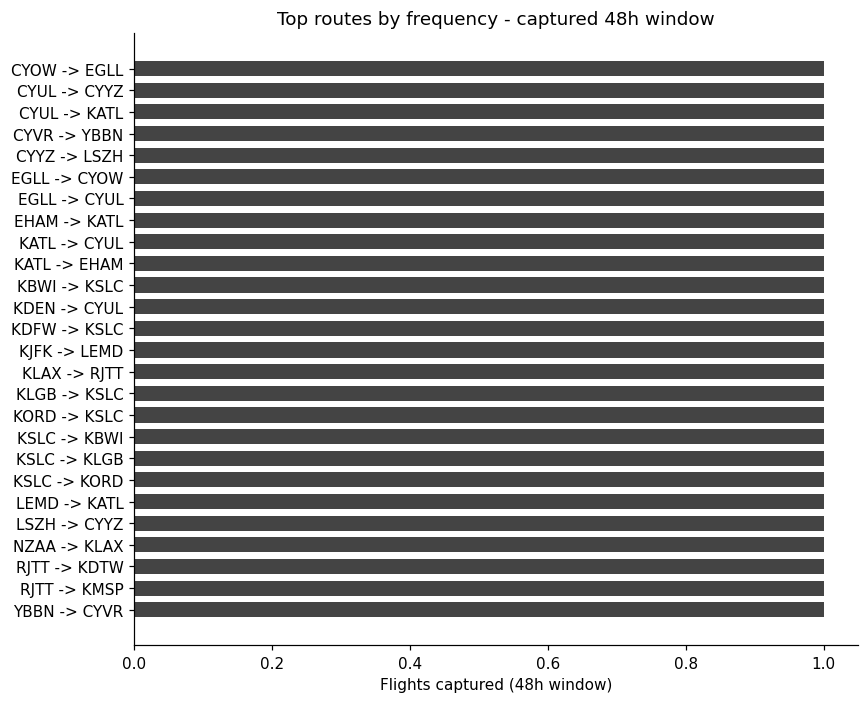

In [3]:
route_counts = (
    complete.groupby(["origin", "destination"]).size()
    .reset_index(name="flights")
    .sort_values("flights", ascending=False)
)
route_counts["route"] = route_counts["origin"] + " -> " + route_counts["destination"]

fig, ax = plt.subplots(figsize=(8, max(3, len(route_counts) * 0.25)))
ax.barh(route_counts["route"], route_counts["flights"], color="#444", height=0.7)
ax.invert_yaxis()
ax.set_xlabel("Flights captured (48h window)")
ax.set_title("Top routes by frequency - captured 48h window")
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

## 2. Rough route map

Hand-curated lat/lon for the airports that appear in this 48-hour window (17 of them). Production map rendering uses Natural Earth coastlines and a Winkel-tripel projection per DESIGN §5; this is the throwaway equirectangular version that confirms the geography is plausible.

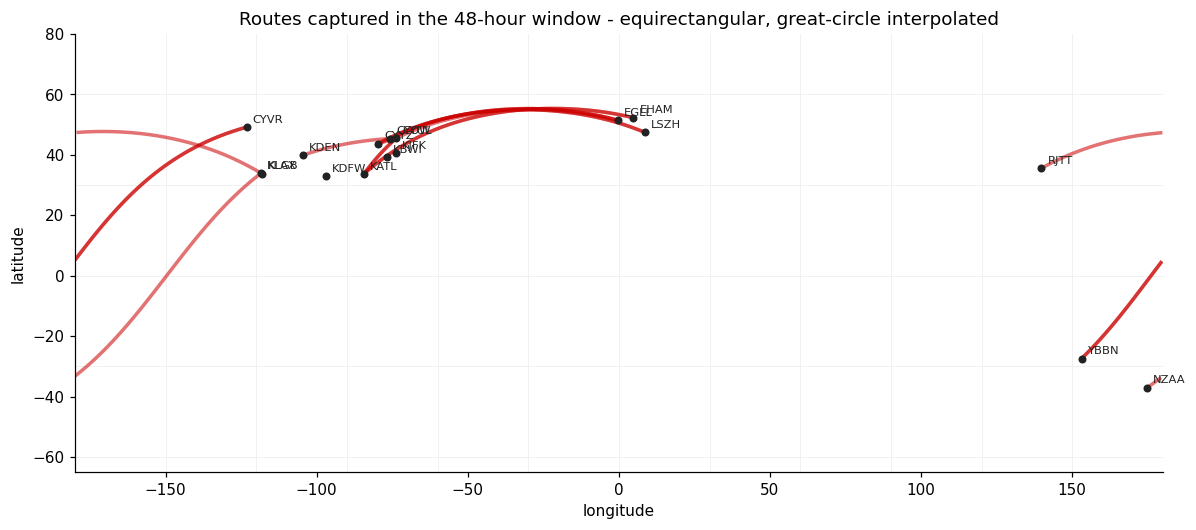

In [4]:
# Hand-curated airport coordinates for the ICAO codes that appear in this dataset.
# Approximate to ~0.1 degree, adequate for an EDA chart.
AIRPORTS = {
    'CYUL': (45.46, -73.74),  # Montreal Trudeau
    'CYYZ': (43.68, -79.63),  # Toronto Pearson
    'CYVR': (49.19, -123.18), # Vancouver
    'CYOW': (45.32, -75.67),  # Ottawa
    'LSZH': (47.46,    8.55), # Zurich
    'EGLL': (51.47,   -0.45), # London Heathrow
    'EHAM': (52.31,    4.76), # Amsterdam Schiphol
    'YBBN': (-27.38, 153.12), # Brisbane
    'KATL': (33.64,  -84.43), # Atlanta
    'KDEN': (39.86, -104.67), # Denver
    'KDFW': (32.90,  -97.04), # Dallas-Fort Worth
    'KBWI': (39.18,  -76.67), # Baltimore
    'KLGB': (33.82, -118.15), # Long Beach
    'KLAX': (33.94, -118.41), # Los Angeles
    'KJFK': (40.64,  -73.78), # New York JFK
    'RJTT': (35.55,  139.78), # Tokyo Haneda
    'NZAA': (-37.01, 174.79), # Auckland
}

def great_circle_points(lat1, lon1, lat2, lon2, n=64):
    """Sample n points along the great-circle arc between two coords.

    Pure spherical interpolation; no projection. Returns (lats, lons).
    """
    phi1, lam1 = math.radians(lat1), math.radians(lon1)
    phi2, lam2 = math.radians(lat2), math.radians(lon2)
    d = 2 * math.asin(math.sqrt(
        math.sin((phi2 - phi1) / 2) ** 2
        + math.cos(phi1) * math.cos(phi2) * math.sin((lam2 - lam1) / 2) ** 2
    ))
    if d == 0:
        return [lat1] * n, [lon1] * n
    lats, lons = [], []
    for i in range(n):
        f = i / (n - 1)
        a = math.sin((1 - f) * d) / math.sin(d)
        b = math.sin(f * d) / math.sin(d)
        x = a * math.cos(phi1) * math.cos(lam1) + b * math.cos(phi2) * math.cos(lam2)
        y = a * math.cos(phi1) * math.sin(lam1) + b * math.cos(phi2) * math.sin(lam2)
        z = a * math.sin(phi1) + b * math.sin(phi2)
        phi = math.atan2(z, math.sqrt(x * x + y * y))
        lam = math.atan2(y, x)
        lats.append(math.degrees(phi))
        lons.append(math.degrees(lam))
    return lats, lons

def split_at_antimeridian(lats, lons):
    """Yield contiguous segments split at antimeridian crossings."""
    seg_lats, seg_lons = [lats[0]], [lons[0]]
    for i in range(1, len(lats)):
        if abs(lons[i] - lons[i - 1]) > 180:
            yield seg_lats, seg_lons
            seg_lats, seg_lons = [lats[i]], [lons[i]]
        else:
            seg_lats.append(lats[i])
            seg_lons.append(lons[i])
    yield seg_lats, seg_lons

fig, ax = plt.subplots(figsize=(11, 5.5))
for lon in range(-180, 181, 30):
    ax.axvline(lon, color="#eee", linewidth=0.5, zorder=0)
for lat in range(-90, 91, 30):
    ax.axhline(lat, color="#eee", linewidth=0.5, zorder=0)

max_freq = route_counts["flights"].max()
for _, r in route_counts.iterrows():
    if r.origin not in AIRPORTS or r.destination not in AIRPORTS:
        continue
    o_lat, o_lon = AIRPORTS[r.origin]
    d_lat, d_lon = AIRPORTS[r.destination]
    lats, lons = great_circle_points(o_lat, o_lon, d_lat, d_lon)
    width = 0.8 + 1.5 * (r.flights / max_freq)
    for seg_lats, seg_lons in split_at_antimeridian(lats, lons):
        ax.plot(seg_lons, seg_lats, color="#c00", alpha=0.55, linewidth=width, zorder=2)

used = set(complete["origin"]) | set(complete["destination"])
for code in used:
    if code not in AIRPORTS:
        continue
    lat, lon = AIRPORTS[code]
    ax.scatter(lon, lat, color="#222", s=18, zorder=3)
    ax.annotate(code, (lon, lat), xytext=(4, 3), textcoords="offset points", fontsize=7.5, color="#222")

ax.set_xlim(-180, 180)
ax.set_ylim(-65, 80)
ax.set_xlabel("longitude")
ax.set_ylabel("latitude")
ax.set_title("Routes captured in the 48-hour window - equirectangular, great-circle interpolated")
ax.set_aspect("equal", adjustable="box")
plt.tight_layout()
fig.savefig(IMG_OUT / "route-map.png", dpi=140, bbox_inches="tight")
plt.show()

## 3. Quick aggregates

In [5]:
print(f"Tails captured:           {flights_df['tail_number'].nunique()}")
print(f"Total flights:            {n_total}")
print(f"Unique routes:            {len(route_counts)}")
print(f"Unique airports touched:  {len(set(complete['origin']) | set(complete['destination']))}")
print()
print("Airline split (by tail prefix):")
ac_flights = flights_df[flights_df['tail_number'].str.startswith('C-')].shape[0]
dl_flights = flights_df[flights_df['tail_number'].str.startswith('N')].shape[0]
ac_tails = flights_df[flights_df['tail_number'].str.startswith('C-')]['tail_number'].nunique()
dl_tails = flights_df[flights_df['tail_number'].str.startswith('N')]['tail_number'].nunique()
print(f"  AC: {ac_flights} flights across {ac_tails} tails")
print(f"  DL: {dl_flights} flights across {dl_tails} tails")
print()
print("Top routes - approximate great-circle distance:")
for _, r in route_counts.head(8).iterrows():
    if r.origin in AIRPORTS and r.destination in AIRPORTS:
        o_lat, o_lon = AIRPORTS[r.origin]
        d_lat, d_lon = AIRPORTS[r.destination]
        phi1, phi2 = math.radians(o_lat), math.radians(d_lat)
        dphi = math.radians(d_lat - o_lat)
        dlam = math.radians(d_lon - o_lon)
        a = math.sin(dphi/2)**2 + math.cos(phi1) * math.cos(phi2) * math.sin(dlam/2)**2
        km = 2 * 6371 * math.asin(math.sqrt(a))
        print(f"  {r.route:<14}  ~{km:>5.0f} km  ({r.flights} flights)")

Tails captured:           8
Total flights:            28
Unique routes:            26
Unique airports touched:  22

Airline split (by tail prefix):
  AC: 12 flights across 4 tails
  DL: 16 flights across 4 tails

Top routes - approximate great-circle distance:
  CYOW -> EGLL    ~ 5347 km  (1 flights)
  CYUL -> CYYZ    ~  507 km  (1 flights)
  CYUL -> KATL    ~ 1599 km  (1 flights)
  CYVR -> YBBN    ~11845 km  (1 flights)
  CYYZ -> LSZH    ~ 6491 km  (1 flights)
  EGLL -> CYOW    ~ 5347 km  (1 flights)
  EGLL -> CYUL    ~ 5216 km  (1 flights)
  EHAM -> KATL    ~ 7065 km  (1 flights)


## What v1.5 / Phase 4 will replace

- The hand-curated `AIRPORTS` dict → a static airport-code table from OurAirports.com (public domain), keyed on ICAO, looked up at build time.
- The equirectangular projection → Winkel-tripel per DESIGN §5, with Natural Earth coastlines as a single SVG path.
- The matplotlib bitmap → server-side static SVG arcs embedded in per-tail Astro pages.
- The 48-hour window → multi-month accumulation once v1.5 nightly collection is enabled.